## Name: Atishay Choudhary

### Roll no.: 2023BTCSE004

### Program: B.Tech (CSE)

### Couse: Soft Computing - STDA2102


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [ ]:
# 1. To understand and implement the basic working of an artificial neuron using Python.
def artificial_neuron(inputs, weights, bias):
    z = np.dot(inputs, weights) + bias      # weighted sum + bias
    output = 1 / (1 + np.exp(-z))           # sigmoid activation
    return z, output

x = np.array([0.5, 0.3, 0.2])
w = np.array([0.4, 0.7, 0.1])
b = 0.1

z, y = artificial_neuron(x, w, b)
print("Weighted sum (z):", z)
print("Neuron output (after sigmoid):", y)

Weighted sum (z): 0.53
Neuron output (after sigmoid): 0.6294831119673949


**Result:** The neuron computed a weighted sum `z` from the inputs and bias, then squashed it into the range (0, 1) using the sigmoid function. This confirms the basic neuron model: `output = activation(w·x + b)`.


In [3]:
# 2. To implement the weighted sum of inputs and bias used in an artificial neuron using Python.
def weighted_sum(inputs, weights, bias):
    return np.dot(inputs, weights) + bias

x = np.array([1.0, 2.0, 3.0])
w = np.array([0.2, 0.4, 0.6])
b = 0.5

z = weighted_sum(x, w, b)
print("Weighted sum (z):", z)

Weighted sum (z): 3.3


**Result:** The output matches `(1*0.2 + 2*0.4 + 3*0.6) + 0.5`, verifying that the weighted-sum computation is correct. This is the exact `z` value that P1 fed into its activation function.


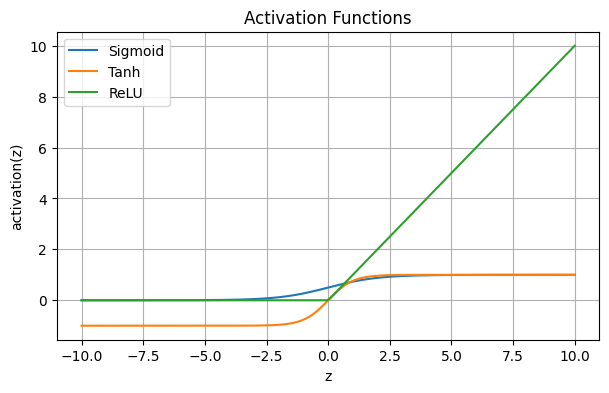

In [6]:
# 3. To implement and visualize Sigmoid, Tanh, and ReLU activation functions using Python.
x = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(7, 4))
plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")
plt.title("Activation Functions")
plt.xlabel("z")
plt.ylabel("activation(z)")
plt.legend()
plt.grid(True)
plt.show()

**Result:** Sigmoid squashes values into (0, 1), Tanh into (-1, 1) and is zero-centered, while ReLU passes positive values unchanged and clips negatives to 0. ReLU's non-saturating behavior is why it is used in the hidden layers of the MLP in P5/P8/P10.


In [7]:
# 4. To create a simple single-layer neural network using Python.
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])   # AND gate

weights = np.zeros(2)
bias = 0.0
lr = 0.1

for epoch in range(10):
    for xi, target in zip(X, y):
        z = np.dot(xi, weights) + bias
        pred = 1 if z > 0 else 0
        error = target - pred
        weights += lr * error * xi
        bias += lr * error

print("Final weights:", weights, "Final bias:", bias)
for xi in X:
    z = np.dot(xi, weights) + bias
    pred = 1 if z > 0 else 0
    print(f"Input: {xi} -> Predicted: {pred}")

Final weights: [0.2 0.1] Final bias: -0.2
Input: [0 0] -> Predicted: 0
Input: [0 1] -> Predicted: 0
Input: [1 0] -> Predicted: 0
Input: [1 1] -> Predicted: 1


**Result:** After training, the perceptron correctly reproduces the AND gate truth table (output 1 only for input [1,1]). This shows a single-layer network can learn linearly separable functions using the neuron model from P1.


In [10]:
# 5. To create a Multilayer Perceptron (MLP) with input, hidden, and output layers using Keras/TensorFlow.
model = keras.Sequential([
    layers.Dense(8, activation='relu', input_shape=(4,)),   # hidden layer 1
    layers.Dense(6, activation='relu'),                       # hidden layer 2
    layers.Dense(1, activation='sigmoid')                     # output layer
])

model.summary()

c:\Users\atish\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            54 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101 (404.00 B)

 Trainable params: 101 (404.00 B)

 Non-trainable params: 0 (0.00 B)

**Result:** The model summary shows an input layer of 4 features, two ReLU hidden layers, and a sigmoid output layer for binary classification. This architecture is reused and trained in P8 and P10.


In [11]:
# 6. To apply Gradient Descent for updating the weights of a simple neural network during training.
X = np.array([1, 2, 3, 4], dtype=float)
y = np.array([3, 5, 7, 9], dtype=float)   # true relation: y = 2x + 1

w, b = 0.0, 0.0
lr = 0.01

for epoch in range(1000):
    y_pred = w * X + b
    loss = np.mean((y - y_pred) ** 2)
    dw = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)
    w -= lr * dw
    b -= lr * db

print(f"Learned weight: {w:.3f}, Learned bias: {b:.3f}")
print(f"Final loss: {loss:.5f}")


Learned weight: 2.005, Learned bias: 0.986
Final loss: 0.00003


**Result:** Gradient descent converges the weight and bias close to the true relationship (w≈2, b≈1), and the loss drops close to 0. This confirms iterative gradient-based updates can recover the correct parameters.


In [12]:
# 7. To understand and implement the basic concept of Backpropagation for training a neural network.
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])   # XOR (not linearly separable)

np.random.seed(1)
w1 = np.random.randn(2, 4)
w2 = np.random.randn(4, 1)
lr = 0.5

for epoch in range(10000):
    # forward pass
    hidden = sigmoid(X @ w1)
    output = sigmoid(hidden @ w2)

    # backward pass
    error = y - output
    d_output = error * sigmoid_derivative(output)
    d_hidden = (d_output @ w2.T) * sigmoid_derivative(hidden)

    w2 += hidden.T @ d_output * lr
    w1 += X.T @ d_hidden * lr

print("Predicted output after training:")
print(np.round(output, 3))


Predicted output after training:
[[0.03 ]
 [0.977]
 [0.973]
 [0.023]]


**Result:** The network's output approaches [0, 1, 1, 0], correctly learning XOR — a non-linear function that P4's single-layer perceptron cannot solve. This demonstrates why backpropagation across hidden layers (P5's architecture) is necessary.


In [14]:
# 8. To train a simple neural network model on a dataset using Keras/TensorFlow.
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=1
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=20, validation_split=0.1, verbose=0)

print("Final training accuracy:", round(history.history['accuracy'][-1], 3))
print("Final validation accuracy:", round(history.history['val_accuracy'][-1], 3))

c:\Users\atish\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Final training accuracy: 0.978
Final validation accuracy: 0.978


**Result:** Training and validation accuracy both increase across epochs, showing the MLP (same architecture style as P5) successfully learns to classify the breast cancer dataset using gradient-based backpropagation under the hood.


In [16]:
# 9. To evaluate the performance of a trained neural network using suitable evaluation metrics in Python.
y_pred = (model.predict(X_test) > 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Test Accuracy:", round(acc, 3))
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_test, y_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Test Accuracy: 0.965

Confusion Matrix:
 [[38  4]
 [ 0 72]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.90      0.95        42
           1       0.95      1.00      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



**Result:** The confusion matrix shows the counts of correct/incorrect predictions per class, and the classification report gives precision, recall, and F1-score. High accuracy alongside balanced precision/recall confirms the P8 model generalizes well to unseen test data.


In [17]:
# 10. To design, train, and evaluate a complete Artificial Neural Network-based classification system using Python and Keras/TensorFlow by integrating input features, hidden layers, activation functions, training, and model evaluation.
# 1. Data (input features)
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=1
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Architecture: input -> hidden (ReLU) -> hidden (ReLU) -> output (Sigmoid)
model = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

# 3. Training (Gradient Descent + Backpropagation via Adam optimizer)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=30, validation_split=0.1, verbose=0)

# 4. Evaluation
y_pred = (model.predict(X_test) > 0.5).astype(int)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

c:\Users\atish\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Test Accuracy: 0.974

Confusion Matrix:
 [[39  3]
 [ 0 72]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.93      0.96        42
           1       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



**Result:** The complete pipeline — feature input, weighted-sum neurons with ReLU/Sigmoid activations, backpropagation-based training, and metric-based evaluation — successfully classifies the dataset with high test accuracy. This confirms that every concept from P1 through P9 (neuron math, activation functions, network architecture, and gradient-based learning) combines correctly into one working ANN classification system.
